In [144]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import warnings
import seaborn as sns 
from pathlib import Path 
from scipy.sparse.linalg import svds
warnings.filterwarnings('ignore')
from ucimlrepo import fetch_ucirepo 
from sklearn.decomposition import PCA, KernelPCA
from sklearn.manifold import MDS,TSNE
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import pairwise_distances
from sklearn.metrics.pairwise import (
    euclidean_distances,
    manhattan_distances,
    cosine_distances
)
from scipy.spatial.distance import pdist, squareform 
import prince 

In [74]:
  
# fetch dataset 
wine = fetch_ucirepo(id=109) 
  
# data (as pandas dataframes) 
X = wine.data.features 
y = wine.data.targets 
  
# metadata 
print(wine.metadata) 
  
# variable information 
print(wine.variables) 
 

df = pd.concat([X, y], axis=1)

print(df.head())

{'uci_id': 109, 'name': 'Wine', 'repository_url': 'https://archive.ics.uci.edu/dataset/109/wine', 'data_url': 'https://archive.ics.uci.edu/static/public/109/data.csv', 'abstract': 'Using chemical analysis to determine the origin of wines', 'area': 'Physics and Chemistry', 'tasks': ['Classification'], 'characteristics': ['Tabular'], 'num_instances': 178, 'num_features': 13, 'feature_types': ['Integer', 'Real'], 'demographics': [], 'target_col': ['class'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 1992, 'last_updated': 'Mon Aug 28 2023', 'dataset_doi': '10.24432/C5PC7J', 'creators': ['Stefan Aeberhard', 'M. Forina'], 'intro_paper': {'ID': 246, 'type': 'NATIVE', 'title': 'Comparative analysis of statistical pattern recognition methods in high dimensional settings', 'authors': 'S. Aeberhard, D. Coomans, O. Vel', 'venue': 'Pattern Recognition', 'year': 1994, 'journal': None, 'DOI': '10.1016/0031-3203(94)90145-7', 'URL': 'https:

In [ ]:
X = df.drop(columns=['class'])
y = df['class']
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

### MCA - Binarização pela média

In [187]:
feats = [c for c in df.columns if c != 'class']
X = df[feats].to_numpy('float')
y = df['class'].to_numpy()

In [188]:
df_bin = pd.DataFrame((X >= X.mean(axis=0)).astype(int), columns=feats).astype(str)

In [189]:
mca = prince.MCA(
    n_components = 2,
    random_state = 42,
    engine = 'scipy'
)

mca.fit(df_bin)

,n_components,2
,n_iter,10
,copy,True
,check_input,True
,random_state,42
,engine,'scipy'
,one_hot,True
,one_hot_prefix_sep,'__'
,one_hot_columns_to_drop,None
,correction,None


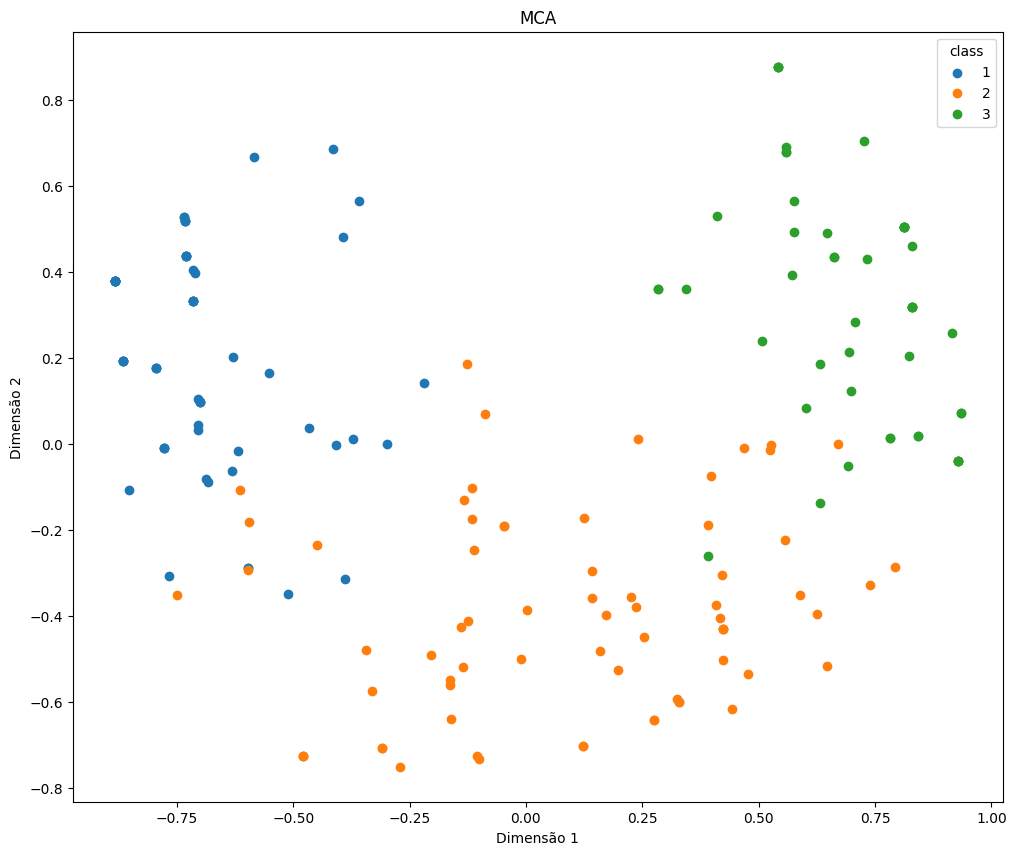

In [190]:
Z = mca.row_coordinates(df_bin).to_numpy()[:, :2]

ev = mca.eigenvalues_

inercia = (
    float(ev[:2].sum() / ev.sum())
    if float(ev.sum()) > 0
    else float('nan')
)

classes = np.unique(y)

plt.figure(figsize=(12,10))

for classe in classes:

    idx = y == classe

    plt.scatter(
        Z[idx, 0],
        Z[idx, 1],
        label=str(classe)
    )

plt.xlabel('Dimensão 1')
plt.ylabel('Dimensão 2')

plt.title(f'MCA')

plt.legend(title='class')

plt.show()

In [198]:
mca.column_coordinates(df_bin).iloc[:,:2].abs()

,0,1
Alcohol__0,0.420307,0.671334
Alcohol__1,0.392895,0.627551
Malicacid__0,0.438751,0.298954
Malicacid__1,0.726885,0.495281
Ash__0,0.067565,0.476040
Ash__1,0.072279,0.509252
Alcalinity_of_ash__0,0.603411,0.159670
Alcalinity_of_ash__1,0.590002,0.156122
Magnesium__0,0.308787,0.484703
Magnesium__1,0.369782,0.580446


In [ ]:
print(f'Inercia total {ev.sum()} ine')

### PCA

In [107]:
pca = PCA(n_components=2, random_state= 42)
Z = pca.fit_transform(X_scaled)
ve = float(pca.explained_variance_ratio_.sum())

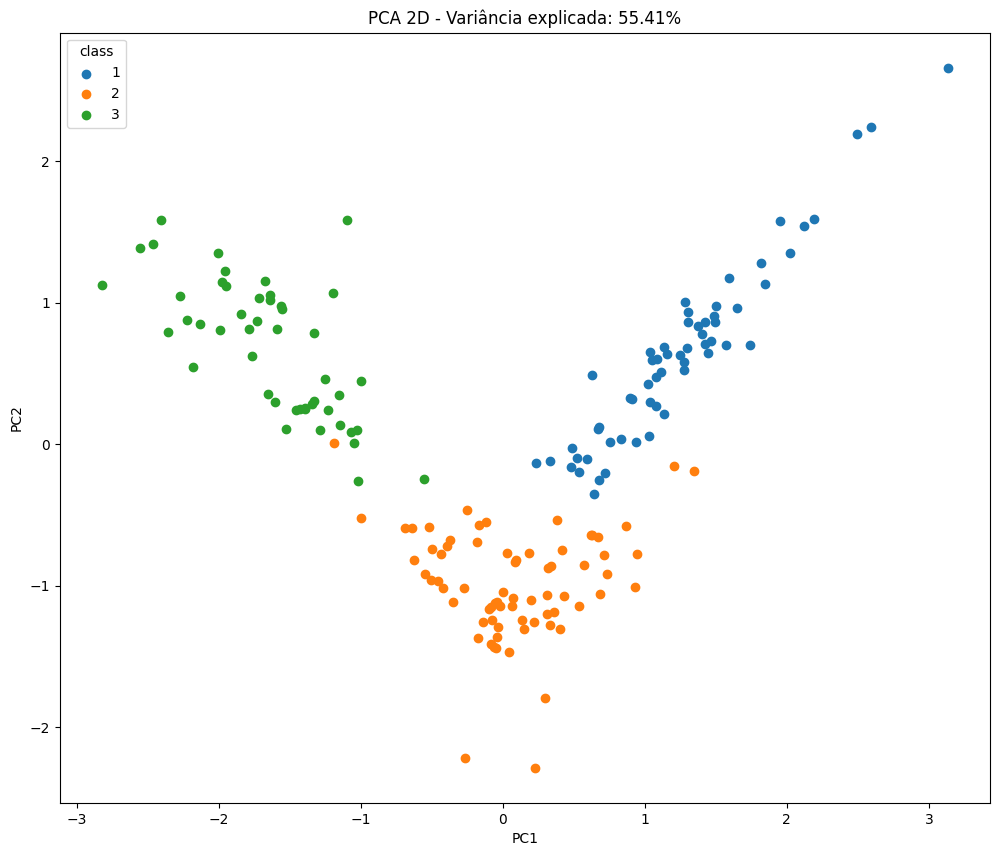

In [185]:
classes = np.unique(y)

plt.figure(figsize=(12,10))

for classe in classes:

    idx = y == classe

    plt.scatter(
        Z[idx, 0],
        Z[idx, 1],
        label=str(classe)
    )

plt.xlabel('PC1')
plt.ylabel('PC2')

plt.title(f'PCA 2D - Variância explicada: {ve:.2%}')

plt.legend(title='class')

plt.show()

### MDS

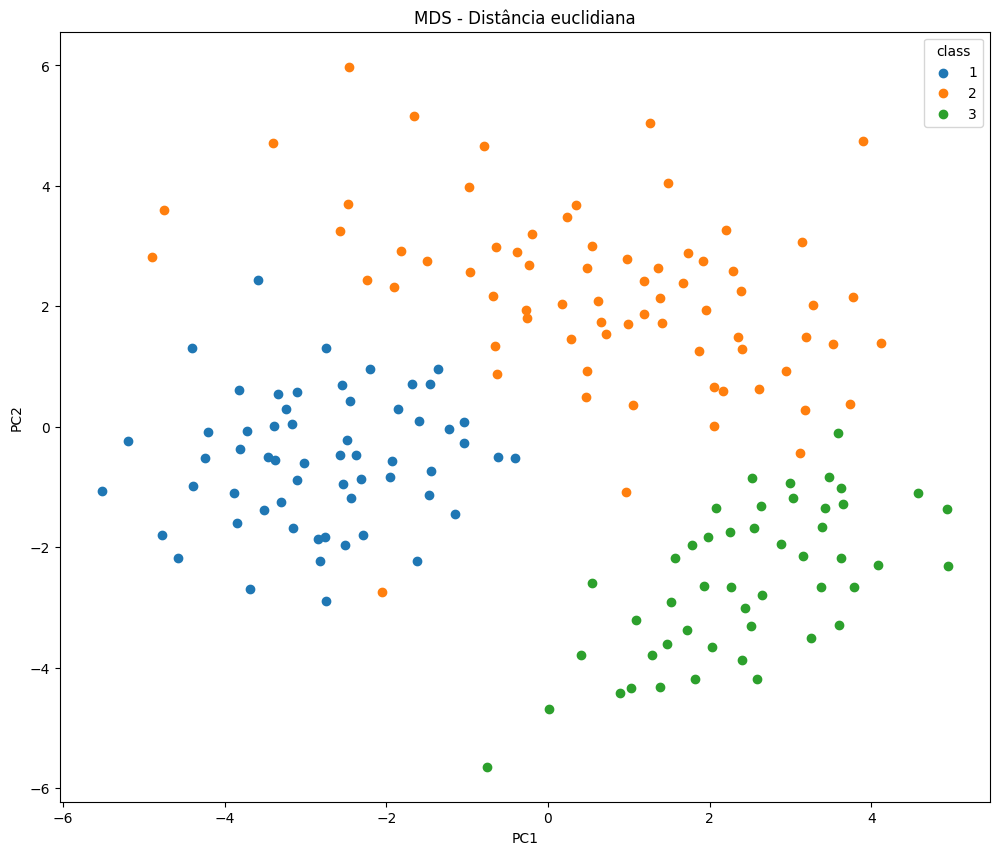

In [148]:
mds = MDS(2, dissimilarity='euclidean', normalized_stress='auto', random_state=42, n_init=4)
Z = mds.fit_transform(X_scaled)

plt.figure(figsize=(12,10))

for classe in classes:

    idx = y == classe

    plt.scatter(
        Z[idx, 0],
        Z[idx, 1],
        label=str(classe)
    )

plt.xlabel('PC1')
plt.ylabel('PC2')

plt.title(f'MDS - Distância euclidiana')

plt.legend(title='class')

plt.show()


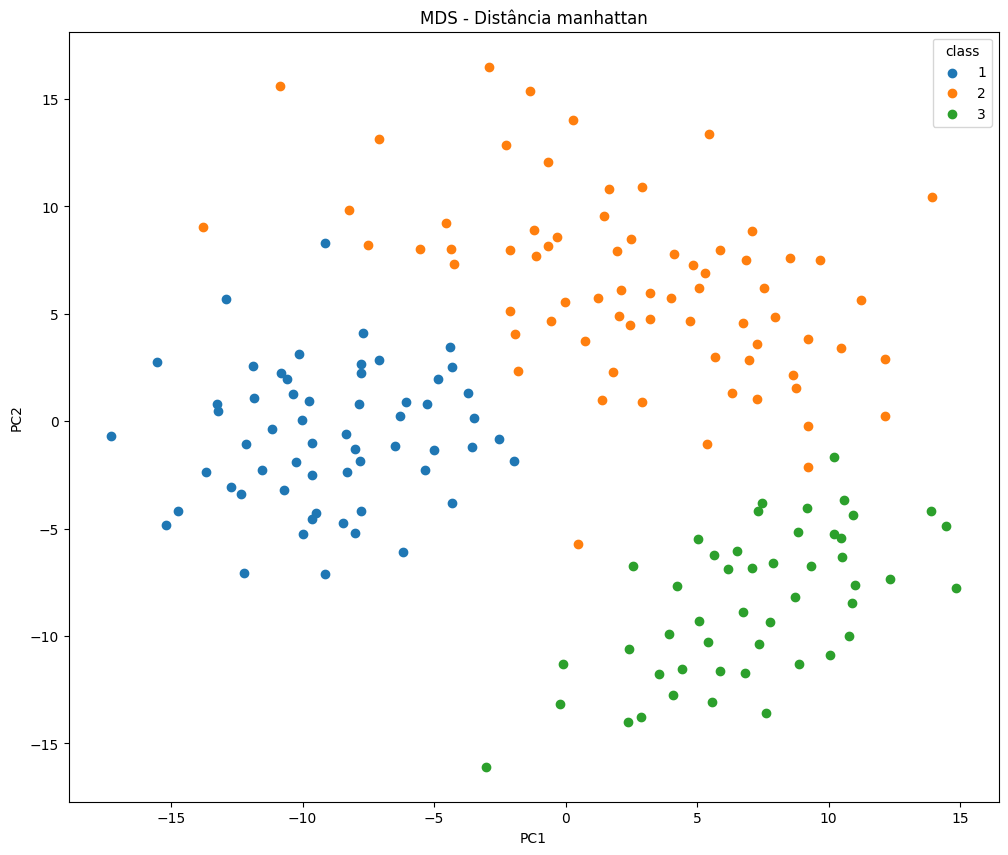

In [149]:
man = pairwise_distances(X_scaled, metric='manhattan')
mds = MDS(2, dissimilarity='precomputed', normalized_stress='auto', random_state=42, n_init=4)
Z = mds.fit_transform(man)

plt.figure(figsize=(12,10))

for classe in classes:

    idx = y == classe

    plt.scatter(
        Z[idx, 0],
        Z[idx, 1],
        label=str(classe)
    )

plt.xlabel('PC1')
plt.ylabel('PC2')

plt.title(f'MDS - Distância manhattan')

plt.legend(title='class')

plt.show()


### SNE

(178, 2)


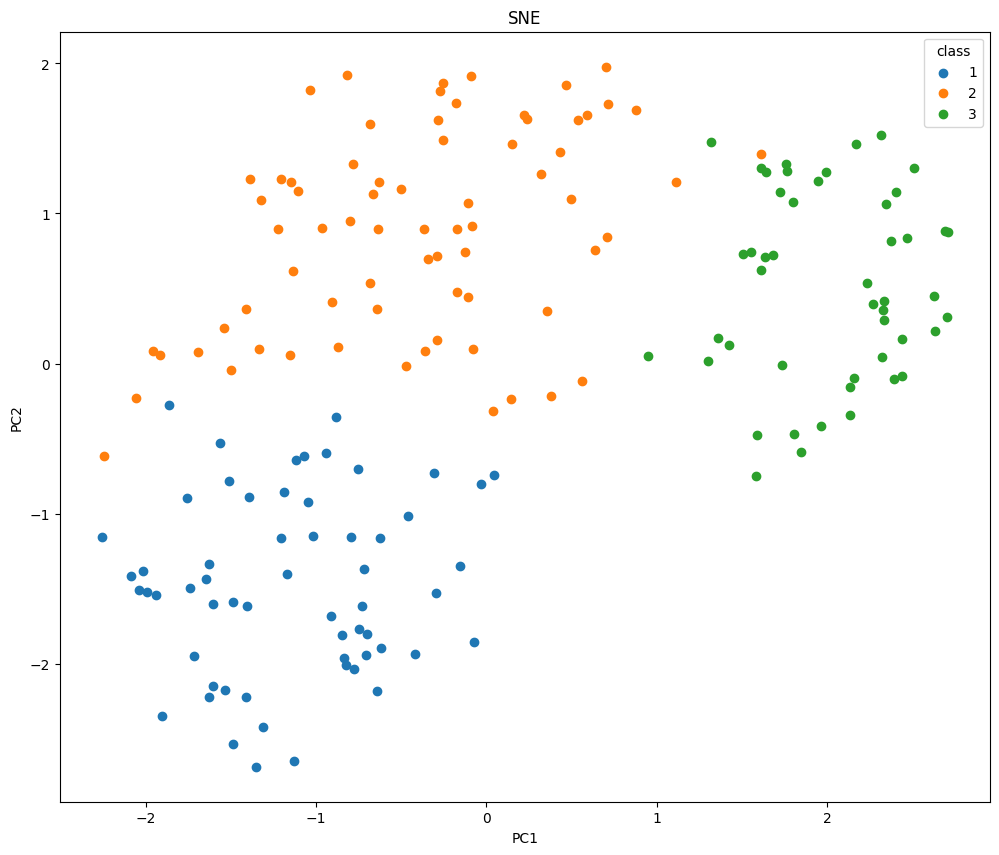

In [164]:
def sne_symmetric_gaussian_2d(
    X,
    perplexity=30.0,
    n_iter=1000,
    learning_rate=10.0,
    random_state=42,
):
    rng = np.random.default_rng(random_state) 
    n = X.shape[0]
    d2_hi = pairwise_distances(X, metric="euclidean", squared=True)
    perp = min(perplexity, (n - 1) / 3.0)
    P = np.zeros((n, n))
    beta = np.ones(n)
    log_u = np.log(perp)

    for i in range(n):
        beta_lo, beta_hi = -np.inf, np.inf
        di = d2_hi[i].copy()
        di[i] = 1e12
        for _ in range(50):
            pi = np.exp(-di * beta[i])
            pi[i] = 0.0
            sump = pi.sum() + 1e-12
            shannon = np.log(sump) + beta[i] * np.sum(di * pi) / sump
            err = shannon - log_u
            if abs(err) < 1e-5:
                break
            if err > 0:
                beta_lo = beta[i]
                beta[i] = (beta[i] + beta_hi) / 2 if beta_hi < np.inf else beta[i] * 2
            else:
                beta_hi = beta[i]
                beta[i] = (beta[i] + beta_lo) / 2 if beta_lo > -np.inf else beta[i] / 2
        pi = np.exp(-di * beta[i])
        pi[i] = 0.0
        P[i] = pi / (pi.sum() + 1e-12)

    P = (P + P.T) / (2.0 * n)
    np.fill_diagonal(P, 0.0)
    P = np.maximum(P, 1e-12)
    P /= P.sum()
    Y = rng.normal(scale=1e-4, size=(n, 2))
    lr = float(learning_rate)

    for it in range(n_iter):
        d2_lo = pairwise_distances(Y, metric="euclidean", squared=True)
        Q = np.exp(-d2_lo)
        np.fill_diagonal(Q, 0.0)
        Q = np.maximum(Q / (Q.sum() + 1e-12), 1e-12)

        PQ = P - Q
        dY = 4.0 * (PQ.sum(axis=1, keepdims=True) * Y - PQ @ Y)
        Y -= lr * dY
        Y -= Y.mean(axis=0)

        if it == n_iter // 2:
            lr *= 0.5

    return Y

 
Z_sne = sne_symmetric_gaussian_2d(X_scaled, perplexity=30.0, n_iter=1000, random_state=42)
print(Z_sne.shape)


plt.figure(figsize=(12,10))

for classe in classes:

    idx = y == classe

    plt.scatter(
        Z_sne[idx, 0],
        Z_sne[idx, 1],
        label=str(classe)
    )

plt.xlabel('PC1')
plt.ylabel('PC2')

plt.title(f'SNE')

plt.legend(title='class')

plt.show()



### T-Sne

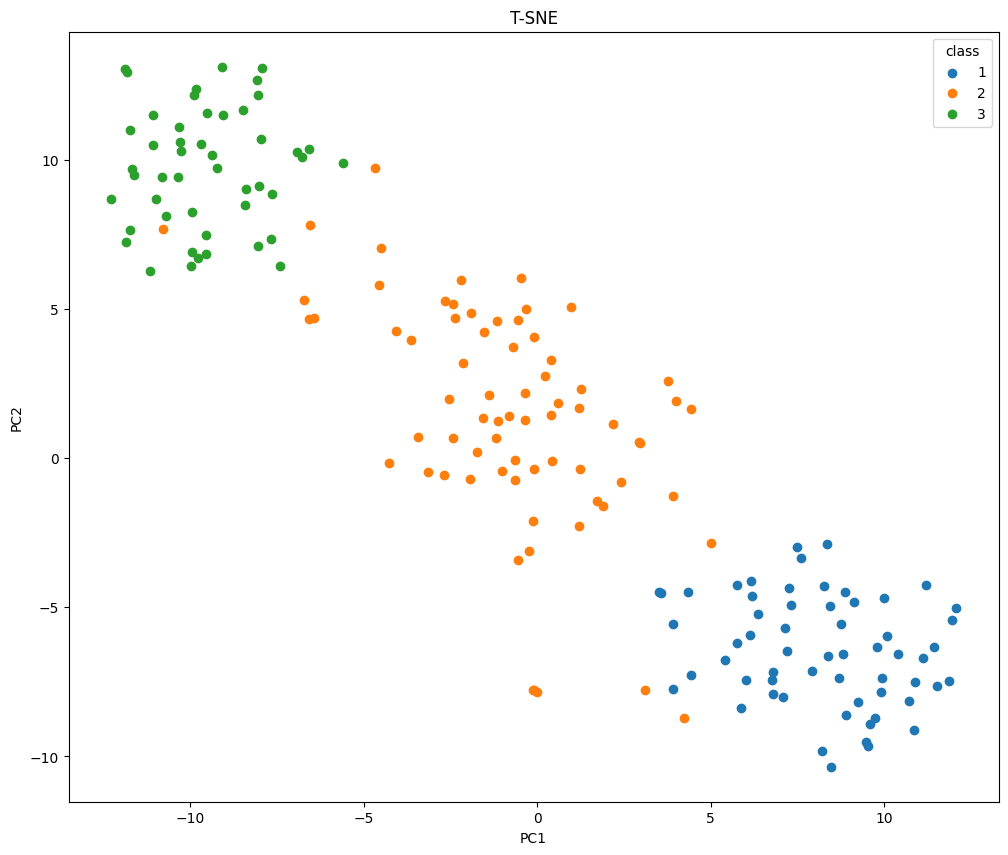

In [165]:
Z_tsne = TSNE(
    n_components=2,
    perplexity=30.0,
    learning_rate='auto',
    init = 'pca',
    random_state= 42,
    max_iter=1000
).fit_transform(X_scaled) 


plt.figure(figsize=(12,10))

for classe in classes:

    idx = y == classe

    plt.scatter(
        Z_tsne[idx, 0],
        Z_tsne[idx, 1],
        label=str(classe)
    )

plt.xlabel('PC1')
plt.ylabel('PC2')

plt.title(f'T-SNE')

plt.legend(title='class')

plt.show()


### Kernel PCA

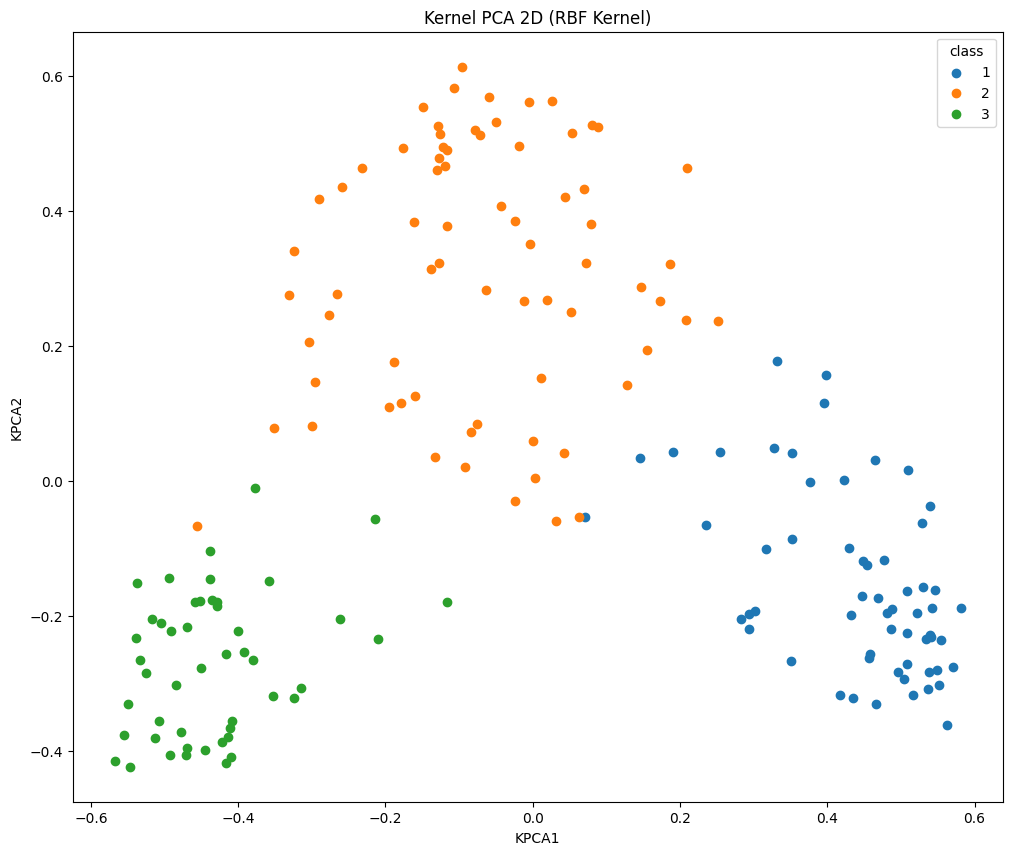

In [183]:
gamma = (1.0 / (X_scaled.shape[1] * X_scaled.var()) if X_scaled.var() > 0 else 0.01)

kpca = KernelPCA(n_components=2,kernel='rbf',gamma=gamma,random_state=42)

Z = kpca.fit_transform(X_scaled)

classes = np.unique(y)

plt.figure(figsize=(12,10))

for classe in classes:

    idx = y == classe

    plt.scatter(
        Z[idx, 0],
        Z[idx, 1],
        label=str(classe)
    )

plt.xlabel('KPCA1')
plt.ylabel('KPCA2')

plt.title('Kernel PCA 2D (RBF Kernel)')

plt.legend(title='class')

plt.show()

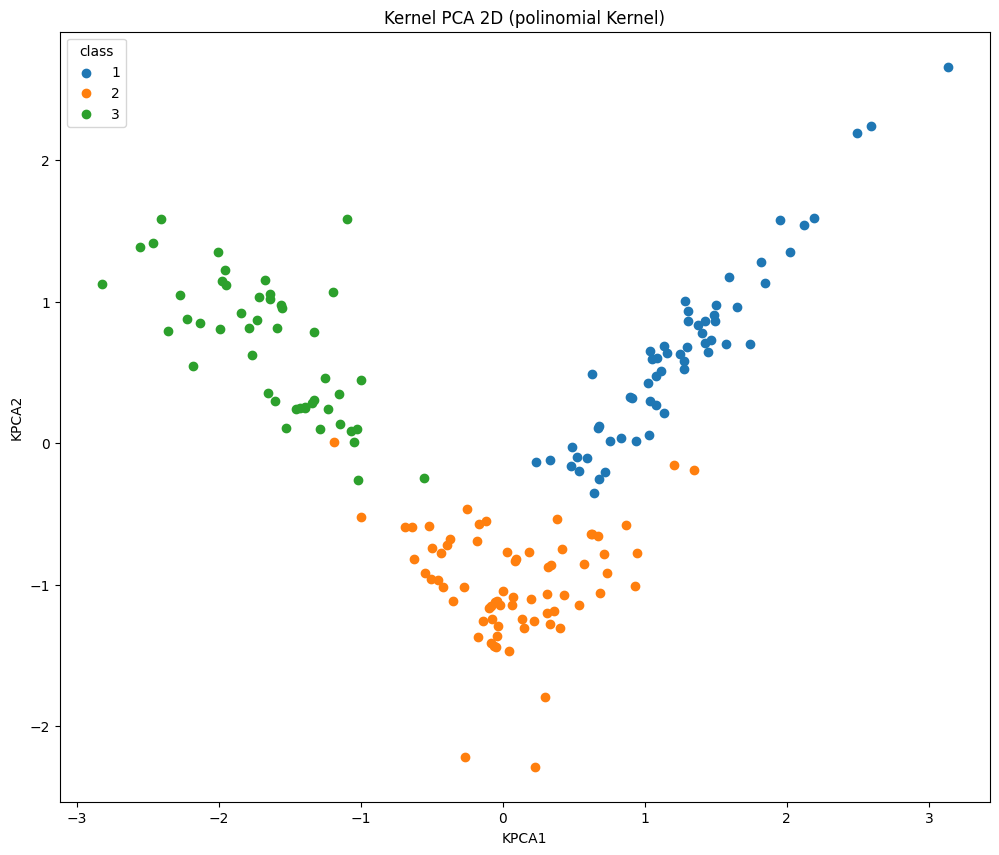

In [184]:
gamma = (1.0 / (X_scaled.shape[1] * X_scaled.var()) if X_scaled.var() > 0 else 0.01)

kpca = KernelPCA(n_components=2,kernel='poly',degree=3,gamma=gamma, coef0=1.0,random_state=42)

Z = kpca.fit_transform(X_scaled)

classes = np.unique(y)

plt.figure(figsize=(12,10))

for classe in classes:

    idx = y == classe

    plt.scatter(
        Z[idx, 0],
        Z[idx, 1],
        label=str(classe)
    )

plt.xlabel('KPCA1')
plt.ylabel('KPCA2')

plt.title('Kernel PCA 2D (polinomial Kernel)')

plt.legend(title='class')

plt.show()